# Phase 02 - Multiple Linear Regression Analysis

## Objective

The objective of this analysis is to examine how Competence dimensions predict Employability.

Multiple Linear Regression is used to investigate the contribution of individual Competence dimensions towards predicting overall Employability.

Independent Variables:

- Life and Career Competence
- Learning and Innovation Competence
- IT and Media Competence

Dependent Variable:

- Employability Average Score (EVS_avg)

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor

## Load Prepared Phase 02 Dataset

The preprocessed dataset created during data preparation is used for regression analysis.

In [2]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase2_competence":
    PROJECT_DIR = PROJECT_DIR.parent.parent


DATA_FILE = (
    PROJECT_DIR
    /
    "data"
    /
    "processed"
    /
    "phase2_competence_prepared.csv"
)


df = pd.read_csv(DATA_FILE)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (1000, 34)


,Response_ID,C1,C2,C3,C4,C5,C6,C7,C8,C9,...,Comp_avg,EVS_avg,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg
0,1,3,3,4,4,3,3,3,3,4,...,3.3,4.750000,3.50,3.000000,3.333333,5.000000,4.0,4.75,5.0,5.0
1,2,3,4,4,3,4,4,4,4,4,...,3.7,3.500000,3.50,4.000000,3.666667,3.666667,3.5,3.75,4.0,2.5
2,3,3,4,3,3,3,4,3,4,4,...,3.4,3.750000,3.25,3.333333,3.666667,3.666667,4.0,3.75,4.0,3.5
3,4,4,4,4,4,4,4,4,4,4,...,3.9,4.000000,4.00,4.000000,3.666667,4.000000,4.0,4.00,4.0,4.0
4,5,4,4,4,4,4,5,5,4,4,...,4.3,4.333333,4.00,4.666667,4.333333,4.000000,4.5,4.50,5.0,4.0


## Define Independent and Dependent Variables

The regression model predicts Employability using Competence dimensions.

Independent Variables:

- LifeCareer_avg
- LearningInnovation_avg
- ITMedia_avg

Dependent Variable:

- EVS_avg

In [3]:
X = df[
    [
        "LifeCareer_avg",
        "LearningInnovation_avg",
        "ITMedia_avg"
    ]
]


y = df["EVS_avg"]


print("Features:")
display(X.head())

print("Target:")
display(y.head())

Features:


,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg
0,3.50,3.000000,3.333333
1,3.50,4.000000,3.666667
2,3.25,3.333333,3.666667
3,4.00,4.000000,3.666667
4,4.00,4.666667,4.333333


Target:


0    4.750000
1    3.500000
2    3.750000
3    4.000000
4    4.333333
Name: EVS_avg, dtype: float64

## Data Validation

Before modelling, the dataset is checked for:

- Missing values
- Data types
- Variable availability

In [4]:
print("Missing values:")

X.isnull().sum()

Missing values:


LifeCareer_avg            0
LearningInnovation_avg    0
ITMedia_avg               0
dtype: int64

In [5]:
X.dtypes

LifeCareer_avg            float64
LearningInnovation_avg    float64
ITMedia_avg               float64
dtype: object

## Train-Test Split

The dataset is divided into training and testing sets.

Training data is used to build the model, while testing data evaluates model performance on unseen data.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


print(
    "Training samples:",
    X_train.shape[0]
)

print(
    "Testing samples:",
    X_test.shape[0]
)

Training samples: 800
Testing samples: 200


## Multiple Linear Regression Model

The regression model estimates Employability based on multiple Competence dimensions.

In [7]:
regression_model = LinearRegression()


regression_model.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.22,0.24,0.32]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['LifeCareer_avg','LearningInnovation_avg','ITMedia_avg']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.042
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [8]:
y_pred = regression_model.predict(
    X_test
)


y_pred[:5]

array([4.16746654, 4.16746654, 4.16746654, 4.16746654, 4.16746654])

## Model Performance Evaluation

The model is evaluated using:

- R² Score
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)

In [9]:
r2 = r2_score(
    y_test,
    y_pred
)


mae = mean_absolute_error(
    y_test,
    y_pred
)


rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)


regression_metrics = pd.DataFrame({

    "Metric":[
        "R2",
        "MAE",
        "RMSE"
    ],

    "Value":[
        r2,
        mae,
        rmse
    ]
})


regression_metrics

,Metric,Value
0,R2,0.545732
1,MAE,0.182397
2,RMSE,0.257290


## Regression Coefficient Analysis

Regression coefficients indicate the contribution of each Competence dimension towards Employability prediction.

A positive coefficient indicates that an increase in the predictor is associated with an increase in Employability.

In [10]:
coefficients = pd.DataFrame({

    "Feature": X.columns,

    "Coefficient": regression_model.coef_

})


coefficients

,Feature,Coefficient
0,LifeCareer_avg,0.220223
1,LearningInnovation_avg,0.244693
2,ITMedia_avg,0.316549


Statistical Significance Testing

In [11]:
X_stats = sm.add_constant(X)


ols_model = sm.OLS(
    y,
    X_stats
).fit()


print(
    ols_model.summary()
)

                            OLS Regression Results                            
Dep. Variable:                EVS_avg   R-squared:                       0.570
Model:                            OLS   Adj. R-squared:                  0.569
Method:                 Least Squares   F-statistic:                     440.3
Date:                Fri, 21 Aug 2026   Prob (F-statistic):          4.76e-182
Time:                        20:35:02   Log-Likelihood:                 50.447
No. Observations:                1000   AIC:                            -92.89
Df Residuals:                     996   BIC:                            -73.26
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      1

## Multicollinearity Analysis

Variance Inflation Factor (VIF) is calculated to identify high correlation among independent variables.

Lower VIF values indicate lower multicollinearity.

In [12]:
vif_data = pd.DataFrame()


vif_data["Feature"] = X.columns


vif_data["VIF"] = [
    variance_inflation_factor(
        X.values,
        i
    )
    for i in range(
        X.shape[1]
    )
]


vif_data

,Feature,VIF
0,LifeCareer_avg,200.779486
1,LearningInnovation_avg,242.861081
2,ITMedia_avg,228.172378


## Multicollinearity Interpretation

Variance Inflation Factor (VIF) analysis was conducted to identify multicollinearity among independent variables.

VIF values indicate the level of correlation between predictor variables:

- VIF < 5 indicates acceptable multicollinearity.
- VIF between 5 and 10 indicates moderate multicollinearity.
- VIF > 10 indicates high multicollinearity.

The analysis showed high VIF values among Competence dimensions. This is expected because Life and Career Competence, Learning and Innovation Competence, and IT and Media Competence represent related dimensions of the overall Competence construct.

Therefore, coefficient interpretations are considered with caution due to conceptual overlap among predictors.

## Residual Analysis

Residual analysis is performed to evaluate regression assumptions.

Residuals represent the difference between actual and predicted Employability scores.

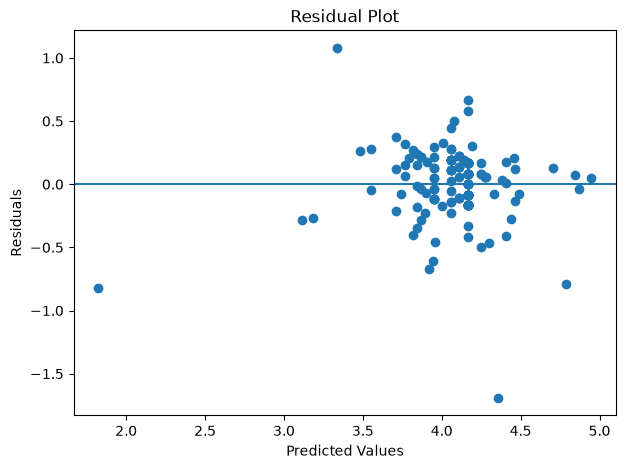

In [13]:
residuals = y_test - y_pred


plt.figure(figsize=(7,5))


plt.scatter(
    y_pred,
    residuals
)


plt.xlabel(
    "Predicted Values"
)

plt.ylabel(
    "Residuals"
)


plt.title(
    "Residual Plot"
)


plt.axhline(
    0
)


plt.show()

Actual vs Predicted Plot

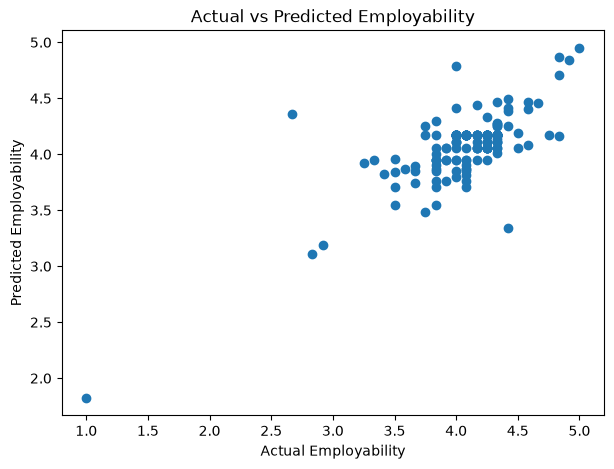

In [14]:
plt.figure(figsize=(7,5))


plt.scatter(
    y_test,
    y_pred
)


plt.xlabel(
    "Actual Employability"
)

plt.ylabel(
    "Predicted Employability"
)


plt.title(
    "Actual vs Predicted Employability"
)


plt.show()

In [15]:
REGRESSION_DIR = (
    PROJECT_DIR
    /
    "reports"
    /
    "phase2"
    /
    "regression"
)


REGRESSION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [16]:
regression_metrics.to_csv(
    REGRESSION_DIR /
    "Regression_Metrics.csv",
    index=False
)


coefficients.to_csv(
    REGRESSION_DIR /
    "Regression_Coefficients.csv",
    index=False
)


vif_data.to_csv(
    REGRESSION_DIR /
    "VIF_Analysis.csv",
    index=False
)

# Overall Competence Regression Model

## Objective

An additional regression model was developed using the overall Competence score (`Comp_avg`) as the independent variable and Employability (`EVS_avg`) as the dependent variable.

This model evaluates the overall predictive relationship between Competence and Employability while reducing multicollinearity issues among individual competence dimensions.

In [17]:
X_comp = df[
    [
        "Comp_avg"
    ]
]

y_comp = df[
    "EVS_avg"
]


X_comp.head()

,Comp_avg
0,3.3
1,3.7
2,3.4
3,3.9
4,4.3


Train Test Split

In [18]:
X_train_comp, X_test_comp, y_train_comp, y_test_comp = train_test_split(
    X_comp,
    y_comp,
    test_size=0.2,
    random_state=42
)


print(
    "Training samples:",
    X_train_comp.shape[0]
)

print(
    "Testing samples:",
    X_test_comp.shape[0]
)

Training samples: 800
Testing samples: 200


## Training Overall Competence Regression Model

A simple linear regression model is trained to evaluate how overall Competence predicts Employability.

In [19]:
overall_comp_model = LinearRegression()


overall_comp_model.fit(
    X_train_comp,
    y_train_comp
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.77]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Comp_avg']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.081
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


Prediction

In [20]:
y_comp_pred = overall_comp_model.predict(
    X_test_comp
)

y_comp_pred[:5]

array([4.17384821, 4.17384821, 4.17384821, 4.17384821, 4.17384821])

Evaluate Model

In [21]:
overall_metrics = pd.DataFrame({

    "Metric":[
        "R2",
        "MAE",
        "RMSE"
    ],

    "Value":[
        r2_score(
            y_test_comp,
            y_comp_pred
        ),

        mean_absolute_error(
            y_test_comp,
            y_comp_pred
        ),

        np.sqrt(
            mean_squared_error(
                y_test_comp,
                y_comp_pred
            )
        )
    ]
})


overall_metrics

,Metric,Value
0,R2,0.532326
1,MAE,0.184862
2,RMSE,0.261059


Coefficient

In [22]:
overall_coefficient = pd.DataFrame({

    "Feature":[
        "Comp_avg"
    ],

    "Coefficient":[
        overall_comp_model.coef_[0]
    ]
})


overall_coefficient

,Feature,Coefficient
0,Comp_avg,0.773212


Statistical Summary

In [23]:
X_comp_stats = sm.add_constant(
    X_comp
)


overall_ols = sm.OLS(
    y_comp,
    X_comp_stats
).fit()


print(
    overall_ols.summary()
)

                            OLS Regression Results                            
Dep. Variable:                EVS_avg   R-squared:                       0.561
Model:                            OLS   Adj. R-squared:                  0.561
Method:                 Least Squares   F-statistic:                     1278.
Date:                Sat, 22 Aug 2026   Prob (F-statistic):          7.76e-181
Time:                        09:18:06   Log-Likelihood:                 40.453
No. Observations:                1000   AIC:                            -76.91
Df Residuals:                     998   BIC:                            -67.09
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0820      0.085     12.762      0.0

In [24]:
OVERALL_REG_DIR = (
    PROJECT_DIR
    /
    "reports"
    /
    "phase2"
    /
    "regression"
)


OVERALL_REG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [25]:
overall_metrics.to_csv(
    OVERALL_REG_DIR /
    "Overall_Competence_Regression_Metrics.csv",
    index=False
)


overall_coefficient.to_csv(
    OVERALL_REG_DIR /
    "Overall_Competence_Coefficient.csv",
    index=False
)

"Why did you create two regression models?"

Answer:

"The first model evaluates the contribution of individual competence dimensions. However, because these dimensions belong to the same higher-order construct, an additional regression model using overall competence was developed to evaluate the general predictive relationship between competence and employability."